In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from torch import nn
from torchsummary import summary
device = "cpu"

In [2]:
with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\train_accuracy.npy", "rb") as f:
    train_accuracy = np.load(f)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\train_loss.npy", "rb") as f:
    train_loss = np.load(f)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\val_accuracy.npy", "rb") as f:
    val_accuracy = np.load(f)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\val_loss.npy", "rb") as f:
    val_loss = np.load(f)

print(train_accuracy.shape)
print(train_loss.shape)
print(val_accuracy.shape)
print(val_loss.shape)

(16,)
(16,)
(16,)
(16,)


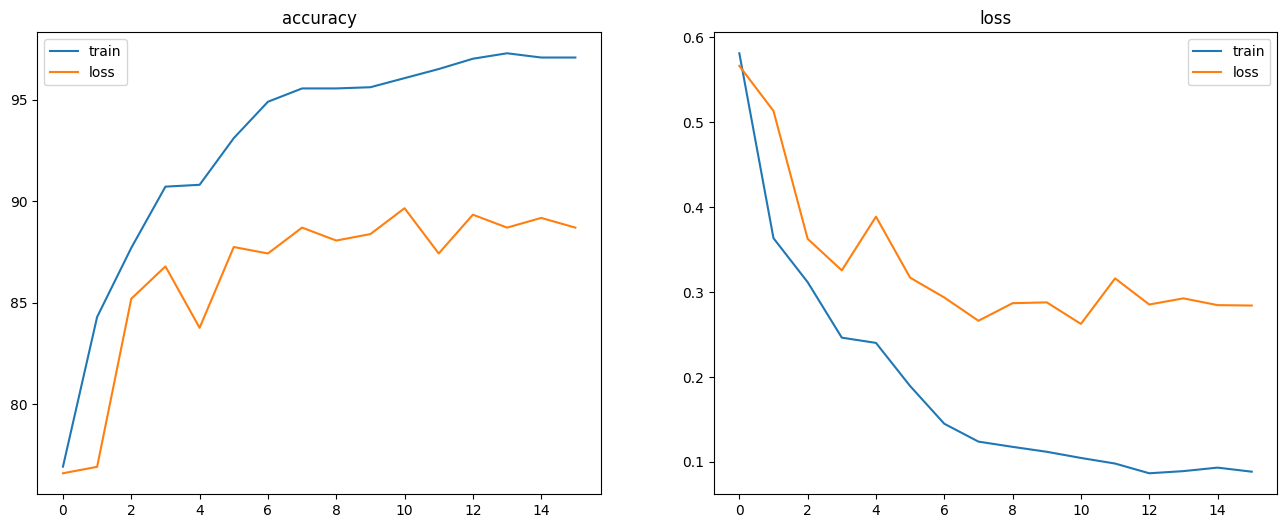

In [3]:
plt.figure(figsize=(16,6))

plt.subplot(121)
plt.plot(train_accuracy, label="train")
plt.plot(val_accuracy, label="loss")
plt.legend()
plt.title("accuracy")

plt.subplot(122)
plt.plot(train_loss, label="train")
plt.plot(val_loss, label="loss")
plt.legend()
plt.title("loss")

plt.show()


In [4]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 16, 3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2))

        self.conv2 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.MaxPool2d(2,2),
            nn.Dropout(0.2))

        self.conv3 = nn.Sequential(
            nn.Conv2d(32,64,3),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.MaxPool2d(2,2))

        self.conv4 = nn.Sequential(
            nn.Conv2d(64,128,3),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.MaxPool2d(2,2),
            nn.Dropout(0.2))

        self.fc1 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*10*10,256),
            nn.ReLU())
        
        self.fc2 = nn.Sequential(
            nn.Linear(256,64),
            nn.ReLU(),
            nn.Dropout(0.2))
        
        self.fc3 = nn.Sequential(
            nn.Linear(64,4))

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)

        return x


model = Net()
model = model.to(device)
model.load_state_dict(torch.load(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\initial_model.pth", map_location="cpu"))
summary(model, (3,200,200))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 198, 198]             448
       BatchNorm2d-2         [-1, 16, 198, 198]              32
              ReLU-3         [-1, 16, 198, 198]               0
         MaxPool2d-4           [-1, 16, 99, 99]               0
            Conv2d-5           [-1, 32, 97, 97]           4,640
       BatchNorm2d-6           [-1, 32, 97, 97]              64
         LeakyReLU-7           [-1, 32, 97, 97]               0
         MaxPool2d-8           [-1, 32, 48, 48]               0
           Dropout-9           [-1, 32, 48, 48]               0
           Conv2d-10           [-1, 64, 46, 46]          18,496
      BatchNorm2d-11           [-1, 64, 46, 46]             128
        LeakyReLU-12           [-1, 64, 46, 46]               0
        MaxPool2d-13           [-1, 64, 23, 23]               0
           Conv2d-14          [-1, 128,

In [5]:
transformer = transforms.Compose([transforms.Resize((200,200)), 
                                  transforms.ToTensor(),
                                  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])

test_data = datasets.ImageFolder(r"C:\Users\wwwat\Desktop\Corn_data\test", transform=transformer)
test_loader = DataLoader(test_data, shuffle=True, batch_size=64)
class_names = test_data.classes
print(class_names)

name = lambda x: class_names[x]

['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


In [6]:
model.eval()

pred_list = []
label_list = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=1)

        predictions = list(predictions.numpy())
        labels = list(labels.numpy())

        pred_list.extend(predictions)
        label_list.extend(labels)

print(classification_report(y_true=label_list, y_pred=pred_list))

              precision    recall  f1-score   support

           0       0.81      0.88      0.85        59
           1       0.98      0.88      0.93        73
           2       0.58      0.52      0.55        21
           3       0.92      1.00      0.96        56

    accuracy                           0.88       209
   macro avg       0.82      0.82      0.82       209
weighted avg       0.88      0.88      0.87       209



<Figure size 2000x1500 with 0 Axes>

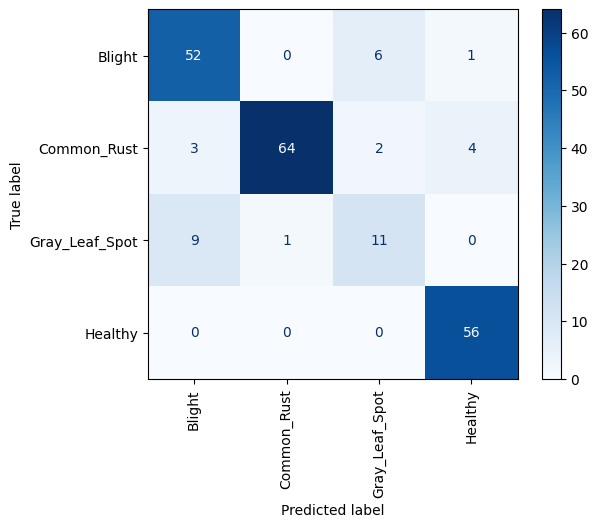

In [7]:
cm = confusion_matrix(y_true=label_list, y_pred=pred_list)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.figure(figsize=(20,15))
disp.plot(cmap=plt.cm.Blues)
plt.xticks(rotation=90)
plt.show()

In [8]:
total = 0
correct = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        total += labels.size(0)

        outputs = model(images)
        for i in range(len(outputs)):
            
            probabilities = nn.functional.softmax(outputs)
            top_p, top_classes = probabilities.topk(2)
            top_classes = top_classes.numpy()

            if labels[i] in top_classes:
                correct += 1

print(f"Rank 2 Accuracy in {total} test images with {correct} True predictions is {correct * 100 / total}%")                    

C:\Users\wwwat\AppData\Local\Temp\ipykernel_11108\2876892722.py:13: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  probabilities = nn.functional.softmax(outputs)


Rank 2 Accuracy in 209 test images with 209 True predictions is 100.0%
